In [1]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

df = pd.read_csv("../data/reviews_clean.csv")
print(df.shape)

(6948, 19)


In [2]:
X = df["Clean Text"]     # input: the cleaned review
y = df["Sentiment"]      # answer: Positive / Neutral / Negative

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Train:", len(X_train), "| Test:", len(X_test))
print("Train mix:", y_train.value_counts(normalize=True).round(3).to_dict())
print("Test mix: ", y_test.value_counts(normalize=True).round(3).to_dict())

Train: 5558 | Test: 1390
Train mix: {'Positive': 0.572, 'Neutral': 0.237, 'Negative': 0.19}
Test mix:  {'Positive': 0.573, 'Neutral': 0.237, 'Negative': 0.19}


In [3]:
models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Linear SVM": LinearSVC(class_weight="balanced"),
}

results = []
trained = {}

for name, model in models.items():
    pipe = Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2)),
        ("model", model),
    ])
    pipe.fit(X_train, y_train)          # learn from training reviews
    pred = pipe.predict(X_test)         # predict the hidden test reviews
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Macro F1": f1_score(y_test, pred, average="macro"),
    })
    trained[name] = pipe

results = pd.DataFrame(results).set_index("Model").round(3).sort_values("Macro F1", ascending=False)
results

,Accuracy,Macro F1
Model,,
Naive Bayes,0.898,0.867
Logistic Regression,0.894,0.865
Linear SVM,0.889,0.859


In [4]:
best_name = results.index[0]
best = trained[best_name]
print("Best model:", best_name)

pred = best.predict(X_test)
print(classification_report(y_test, pred))

Best model: Naive Bayes
              precision    recall  f1-score   support

    Negative       0.87      0.95      0.91       264
     Neutral       0.90      0.64      0.75       330
    Positive       0.91      0.99      0.94       796

    accuracy                           0.90      1390
   macro avg       0.89      0.86      0.87      1390
weighted avg       0.90      0.90      0.89      1390



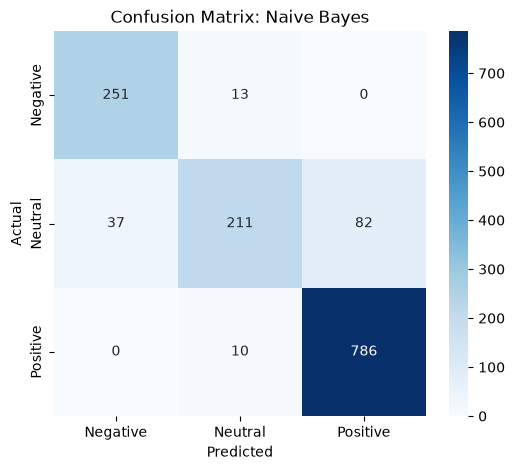

In [5]:
labels = ["Negative", "Neutral", "Positive"]
cm = confusion_matrix(y_test, pred, labels=labels)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix: {best_name}")
plt.show()

In [6]:
lr = trained["Logistic Regression"]
clf = lr.named_steps["model"]
vocab = lr.named_steps["tfidf"].get_feature_names_out()

for i, sentiment in enumerate(clf.classes_):
    top = np.argsort(clf.coef_[i])[-10:][::-1]
    print(f"{sentiment}: {[vocab[j] for j in top]}")

Negative: ['disappointed', 'not', 'arrived damaged', 'poor', 'waste', 'delivered', 'wrong', 'not happy', 'bad', 'useless']
Neutral: ['average', 'not bad', 'fine', 'acceptable', 'okay', 'packaging damaged', 'expected', 'decent', 'ok', 'overpriced']
Positive: ['sturdy', 'amazing', 'good', 'excellent quality', 'excellent', 'very happy', 'very', 'super', 'satisfied', 'very satisfied']


In [7]:
keep_words = {"not", "no", "nor", "never", "cannot", "very", "too", "least", "less", "more", "most"}
stop_words = ENGLISH_STOP_WORDS - keep_words

def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    return " ".join(w for w in text.split() if w not in stop_words and len(w) > 1)

new_reviews = [
    "The chair is very comfortable and delivery was quick",
    "Worst phone ever, stopped working in two days. I want a refund",
    "The table is okay, nothing special",
    "Not happy with the packaging, the box was torn",
    "Good product but delivery was late",
]

pd.DataFrame({
    "Review": new_reviews,
    "Predicted": best.predict([clean_text(r) for r in new_reviews]),
})

,Review,Predicted
0,The chair is very comfortable and delivery was...,Positive
1,"Worst phone ever, stopped working in two days....",Negative
2,"The table is okay, nothing special",Neutral
3,"Not happy with the packaging, the box was torn",Negative
4,Good product but delivery was late,Neutral


In [8]:
joblib.dump(best, "../models/sentiment_model.pkl")
print("Model saved!")

Model saved!
